In [1]:
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import warnings
import pandas as pd
import os
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from enum import Enum
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from collections import defaultdict
import os
import time # 描画のために追加
from stable_baselines3 import PPO


In [2]:
# ActionTypeの定義 (元のノートブックにある場合)
class ActionType(Enum):
    DO_NOTHING = 0
    DO_TASK = 1

In [3]:
import gymnasium as gym # gymnasium を gym という名前でインポートすることを推奨
from gymnasium import spaces
import numpy as np
import time
from enum import Enum # ActionType を使うために必要
import warnings # 警告を無視するために必要 (元のコードより)
import pandas as pd # Pandasの表示オプション設定のために必要 (元のコードより)

# Pandasの表示オプション設定 (元のコードより)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# 警告フィルタ (元のコードより)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)


# ActionType Enum の定義 (このクラス定義の前に必要です)
class ActionType(Enum):
    DO_NOTHING = 0
    DO_TASK = 1


class DummyEnvWithIntervention(gym.Env):
    metadata = {'render_modes': ['human', 'rgb_array'], 'render_fps': 4}

    def __init__(self, max_steps=100, intervention_type=0, co_score=0.5, render_mode=None):
        super().__init__() # gymnasium.Env の __init__ を呼び出す
        self.max_steps = max_steps
        self.intervention_type = intervention_type
        self.co_score = co_score
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(low=0, high=1, shape=(1,), dtype=np.float32)

        self.current_step = 0
        self.consecutive_inaction_steps = 0
        self.state = np.array([0.0], dtype=np.float32)
        self.task_completed = False
        self.intervention_occurred_in_episode = False

        self.last_action_taken = None
        self.last_reward_received = 0
        self.intervention_triggered_this_step = False
        self.task_completed_this_step = False

        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        # self.render_mode = render_mode # 2行目は重複しているので削除

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.consecutive_inaction_steps = 0
        self.state = np.array([0.0], dtype=np.float32)
        self.task_completed = False
        self.intervention_occurred_in_episode = False

        self.last_action_taken = None
        self.last_reward_received = 0
        self.intervention_triggered_this_step = False
        self.task_completed_this_step = False

        if self.render_mode == "human":
            self._render_frame() # _render_frame を呼び出す (現状はほぼsleepのみ)

        info = {} # gymnasium では reset も info を返す
        return self.state, info # 修正点1: obs, info を返す

    def step(self, action):
        self.current_step += 1
        self.last_action_taken = action
        self.intervention_triggered_this_step = False
        self.task_completed_this_step = False

        reward = 0
        # done = False # 古い gym の変数なので、terminated と truncated に置き換える

        info = {
            'intervention_occurred': False, # これはステップ内で更新される可能性あり
            'consecutive_inaction_steps_before_action': self.consecutive_inaction_steps,
            'co_score': self.co_score,
            'intervention_type': self.intervention_type
        }

        intervention_penalty = -5
        inaction_penalty = -1
        completion_reward = 100

        perform_action_due_to_intervention = False
        # ... (既存の介入ロジックはそのまま) ...
        if self.intervention_type == 1: # 弱い介入
            if self.co_score < 0.4 and self.current_step > self.max_steps * 0.1 and self.consecutive_inaction_steps > 2:
                perform_action_due_to_intervention = True
                self.intervention_triggered_this_step = True
            elif self.consecutive_inaction_steps > 5:
                perform_action_due_to_intervention = True
                self.intervention_triggered_this_step = True
        elif self.intervention_type == 2: # 強い介入
            if self.co_score < 0.6 and self.current_step > self.max_steps * 0.05 and self.consecutive_inaction_steps > 1:
                perform_action_due_to_intervention = True
                self.intervention_triggered_this_step = True
            elif self.consecutive_inaction_steps > 3:
                perform_action_due_to_intervention = True
                self.intervention_triggered_this_step = True

        if perform_action_due_to_intervention:
            action_to_execute = ActionType.DO_TASK.value # action引数を上書き
            reward += intervention_penalty
            info['intervention_occurred'] = True
            self.intervention_occurred_in_episode = True
            self.consecutive_inaction_steps = 0
        elif action == ActionType.DO_TASK.value: # action引数を使用
            action_to_execute = action # 明示的に
            self.consecutive_inaction_steps = 0
            if np.random.rand() < self.co_score:
                reward += completion_reward
                self.task_completed = True
                self.task_completed_this_step = True
                # done = True # terminated で表現
            else:
                reward += 0
        else: # action == ActionType.DO_NOTHING.value
            action_to_execute = action # 明示的に
            self.consecutive_inaction_steps += 1
            reward += inaction_penalty

        # 修正点2: terminated と truncated の定義
        terminated = self.task_completed # タスク完了が真の終了条件
        truncated = (self.current_step >= self.max_steps) and not self.task_completed # 最大ステップ到達は打ち切り

        if truncated and not self.task_completed: # 最大ステップで未完了の場合のペナルティ
             reward -= 20 # このロジックは元のif not done and ... と同等

        self.last_reward_received = reward

        if self.render_mode == "human":
            self._render_frame() # _render_frame を呼び出す (現状はほぼsleepのみ)

        return self.state, reward, terminated, truncated, info # 修正点2: 5つの値を返す

    def render(self): # このメソッドはシミュレーションループから env.render() で明示的に呼ばれることを想定
        if self.render_mode == "human":
            print(f"\n--- Step: {self.current_step}/{self.max_steps} ---")
            print(f"CO Score: {self.co_score:.2f} | Intervention Type: {self.intervention_type}")
            if self.last_action_taken is not None:
                action_text = "DO_TASK" if self.last_action_taken == ActionType.DO_TASK.value else "DO_NOTHING"
                print(f"Action Taken: {action_text} ({self.last_action_taken})")
            else:
                print("Action Taken: None (Start of Episode)")
            print(f"Reward Received: {self.last_reward_received}")
            print(f"Consecutive Inaction: {self.consecutive_inaction_steps}")

            if self.intervention_triggered_this_step:
                print(f"*** INTERVENTION TRIGGERED (Type: {self.intervention_type}) ***")
            if self.task_completed_this_step:
                print("$$$ TASK COMPLETED! $$$")

            # エピソード終了状態の表示
            if self.task_completed : # terminated に相当
                 print("--- Episode Ended: Task completed ---")
            elif self.current_step >= self.max_steps: # truncated に相当
                print("--- Episode Ended: Max steps reached without completion ---")

            time.sleep(0.05)

    def _render_frame(self): # このメソッドは reset と step から自動的に呼ばれる
        if self.render_mode == "human":
            # ここに reset や step 毎に必ず表示したい最小限の情報や、
            # 描画更新のためのウェイトなどを記述できます。
            # 現状はほぼ sleep のみです。
            time.sleep(0.05)

    def close(self):
        pass

In [4]:
import gymnasium as gym # gymnasium を gym という名前でインポート
from gymnasium import spaces
import numpy as np
import time
import warnings # ユーザーコードにあったため追加
# from enum import Enum # ActionType などで Enum を使う場合は必要

# ActionType の定義 (もしあれば、このクラス定義の前に配置)
# class ActionType(Enum):
#     ACTION_0 = 0
#     ACTION_1 = 1
#     ACTION_2 = 2 # n_actions=3 の場合

class SimplifiedTaskJITAIEnv(gym.Env):
    metadata = {'render_modes': ['human', 'rgb_array'], 'render_fps': 4} # rgb_arrayも追加しておくと良い

    def __init__(self,
                 n_actions=3,
                 max_episode_length=90,
                 seed=0,
                 co_score=0.5,
                 total_task_work=230.0,
                 delta_d_base=0.02,
                 epsilon_d_base=0.05,
                 D_threshold_base=0.2,
                 d_increase_on_inaction_base=0.002,
                 co_effect_on_d_increase_inaction_multiplier=-0.5,
                 inaction_steps_threshold=5,
                 base_prob_start_action_base=0.6,
                 intervention_boost_to_prob_start_base=[0.0, 0.1, 0.25],
                 urgency_factor_base=0.3,
                 mu_s_base=4.1,
                 rho1_base=2.0,
                 rho2_base=5.0,
                 co_effect_on_delta_d_multiplier=0.3,
                 co_effect_on_epsilon_d_multiplier=0.5,
                 co_effect_on_D_threshold_multiplier=1.5,
                 co_effect_on_base_prob_start_multiplier=0.2,
                 co_effect_on_intervention_boost_multiplier=0.1,
                 co_effect_on_urgency_factor_multiplier=-0.4,
                 co_effect_on_mu_s_multiplier=0.2,
                 co_effect_on_rho1_multiplier=0.1,
                 co_effect_on_rho2_multiplier=0.1,
                 init_d=0.1,
                 chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
                 n_version=0,
                 s_noise_std_base=0.0,
                 co_effect_on_s_noise_std_multiplier=0.0,
                 intervention_cost=0.1,
                 render_mode=None): # <<-- render_mode 引数を追加
        super().__init__()

        self.max_episode_length = max_episode_length
        self.n_actions = n_actions
        self.chosen_obs_names = chosen_obs_names
        self.n_version = n_version

        self.co_score = np.clip(co_score, 0.0, 1.0)
        self.current_CO = self.co_score # __init__ で一度設定

        self.delta_d_base = delta_d_base
        self.epsilon_d_base = epsilon_d_base
        self.D_threshold_base = D_threshold_base
        self.d_increase_on_inaction_base = d_increase_on_inaction_base
        self.co_effect_on_d_increase_inaction_multiplier = co_effect_on_d_increase_inaction_multiplier
        self.inaction_steps_threshold = inaction_steps_threshold

        self.base_prob_start_action_base = base_prob_start_action_base
        self.intervention_boost_to_prob_start_base = np.array(intervention_boost_to_prob_start_base)
        if len(self.intervention_boost_to_prob_start_base) != n_actions:
            raise ValueError("Length of intervention_boost_to_prob_start_base must match n_actions.")
        self.urgency_factor_base = urgency_factor_base
        self.mu_s_base = mu_s_base
        self.rho1_base = rho1_base
        self.rho2_base = rho2_base
        self.total_task_work = total_task_work
        self.s_noise_std_base = s_noise_std_base

        self.co_effect_on_delta_d_multiplier = co_effect_on_delta_d_multiplier
        self.co_effect_on_epsilon_d_multiplier = co_effect_on_epsilon_d_multiplier
        self.co_effect_on_D_threshold_multiplier = co_effect_on_D_threshold_multiplier
        self.co_effect_on_base_prob_start_multiplier = co_effect_on_base_prob_start_multiplier
        self.co_effect_on_intervention_boost_multiplier = co_effect_on_intervention_boost_multiplier
        self.co_effect_on_urgency_factor_multiplier = co_effect_on_urgency_factor_multiplier
        self.co_effect_on_mu_s_multiplier = co_effect_on_mu_s_multiplier
        self.co_effect_on_rho1_multiplier = co_effect_on_rho1_multiplier
        self.co_effect_on_rho2_multiplier = co_effect_on_rho2_multiplier
        self.co_effect_on_s_noise_std_multiplier = co_effect_on_s_noise_std_multiplier

        self.init_d = init_d
        self.init_s = 0.0
        self.init_task_progress = 0.0
        
        self.intervention_cost = intervention_cost

        self.seed = seed # 初期シード
        self.rng1 = np.random.default_rng(self.seed) # __init__で一度初期化

        self.current_t = 0
        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.consecutive_inaction_steps = 0

        self.action_space = spaces.Discrete(self.n_actions)
        min_obs_values, max_obs_values = self.extract_min_max()
        self.observation_space = spaces.Box(
            low=np.array(min_obs_values, dtype=np.float32),
            high=np.array(max_obs_values, dtype=np.float32),
            dtype=np.float32
        )
        self._initialize_operational_params() # 初期パラメータ設定

        # --- レンダリングモード設定 ---
        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        # --- ここまで ---

        # --- レンダリング用に直前の情報を保持する変数 (適宜追加) ---
        self.last_agent_action = None # agent_action を保持
        self.last_step_reward = 0.0
        # --- ここまで ---


    def _initialize_operational_params(self):
        # このメソッドは reset で呼ばれるため、co_score に応じた調整は reset で行う
        self.delta_d, self.epsilon_d, self.D_threshold = 0.0, 0.0, 0.0
        self.base_prob_start_action = 0.0
        self.intervention_boost_to_prob_start = np.zeros(self.n_actions)
        self.urgency_factor = 0.0
        self.mu_s, self.rho1, self.rho2 = 0.0, 0.0, 0.0
        self.s_noise_std = 0.0

    def _adjust_param(self, base_val, multiplier, co_factor):
        return base_val * (1 + co_factor * multiplier)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None: # 引数でseedが指定されたら、それを使用
            self.seed = seed
        # self.seed はインスタンスの初期seed、または引数で与えられたseed
        # rngの再初期化時は、エピソードごとに異なる状態にするため工夫が必要な場合もあるが、
        # Gymnasiumのsuper().reset(seed=seed)が内部で適切に処理してくれることを期待する。
        # ここでは、ユーザーの元のコードに合わせてrng1を再生成する
        self.rng1 = np.random.default_rng(self.seed) # self.seed を使う

        self._initialize_operational_params() # パラメータを一度リセット
        co_factor = self.co_score - 0.5 # co_score は __init__ で設定されたものを使用

        self.D_threshold = np.clip(self.D_threshold_base, 0.001, 0.999)
        
        self.delta_d = np.clip(self._adjust_param(self.delta_d_base, self.co_effect_on_delta_d_multiplier, co_factor), 0.0, 0.999)
        self.epsilon_d = np.clip(self._adjust_param(self.epsilon_d_base, self.co_effect_on_epsilon_d_multiplier, co_factor), 0.0, 0.999)

        self.base_prob_start_action = np.clip(self._adjust_param(self.base_prob_start_action_base, self.co_effect_on_base_prob_start_multiplier, co_factor), 0.01, 0.99)
        boost_adjustment = (1 + co_factor * self.co_effect_on_intervention_boost_multiplier)
        self.intervention_boost_to_prob_start = np.clip(self.intervention_boost_to_prob_start_base * boost_adjustment, 0.0, 0.5)
        self.urgency_factor = self._adjust_param(self.urgency_factor_base, self.co_effect_on_urgency_factor_multiplier, co_factor)
        self.urgency_factor = np.clip(self.urgency_factor, -0.5, 0.5) # 元のコードではマイナスもあり得る
        self.mu_s = np.clip(self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor), 0.1, None) # 下限0.1
        self.rho1 = np.clip(self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor), 0.0, None) # 下限0.0
        self.rho2 = np.clip(self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor), 0.0, None) # 下限0.0

        if self.n_version == 1:
            self.s_noise_std = np.clip(self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor), 0.0, None) # 下限0.0
        else:
            self.s_noise_std = 0.0

        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.current_t = 0
        self.consecutive_inaction_steps = 0

        # レンダリング用変数のリセット
        self.last_agent_action = None
        self.last_step_reward = 0.0

        obs = self._get_observation()
        info = self._get_info() # 最初に基本情報を取得
        info.update({"message": "Environment reset."}) # メッセージを追加

        # reset時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()
            
        return obs, info

    def step(self, agent_action):
        a = int(agent_action)
        if not (0 <= a < self.n_actions): # Action space validation
            raise ValueError(f"Action {a} is out of range for n_actions={self.n_actions}")

        self.last_agent_action = a # 直前の行動を保存

        task_progress_t = self.TaskProgress # ステップ開始時の進捗

        time_remaining_normalized = (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        urgency_effect_on_prob_start = 0.0
        urgency_threshold = 0.3 # この値はパラメータ化しても良い
        if time_remaining_normalized < urgency_threshold and time_remaining_normalized >= 0:
            urgency_level = 1.0 - (time_remaining_normalized / urgency_threshold)
            urgency_effect_on_prob_start = self.urgency_factor * urgency_level

        prob_start_action_calculated = self.base_prob_start_action \
                                     + self.intervention_boost_to_prob_start[a] \
                                     + urgency_effect_on_prob_start
        prob_start_action_calculated = np.clip(prob_start_action_calculated, 0.01, 0.99)

        s_this_step = 0.0
        action_started_this_step = False
        if self.rng1.random() < prob_start_action_calculated: # rng1を使用
            action_started_this_step = True
            s_next_mu_calculated = self.mu_s
            if a == 1: s_next_mu_calculated += self.rho1 # 行動タイプ1 (介入1と仮定)
            elif a == 2: s_next_mu_calculated += self.rho2 # 行動タイプ2 (介入2と仮定)
            # 注意: a==0 の場合は s_next_mu_calculated は self.mu_s のまま。これが意図通りか確認。
            
            s_final_next_if_started = s_next_mu_calculated
            if self.n_version == 1 and self.s_noise_std > 0:
                s_final_next_if_started = max(0.0, self.rng1.normal(s_next_mu_calculated, self.s_noise_std)) # rng1を使用
            s_this_step = max(0.0, s_final_next_if_started)
        self.S = s_this_step

        d_increased_this_step_due_to_inaction = 0.0 # 初期化
        if not action_started_this_step:
            self.consecutive_inaction_steps += 1
            if self.consecutive_inaction_steps >= self.inaction_steps_threshold: # 閾値以上でD増加
                co_factor = self.co_score - 0.5
                actual_d_increase = self._adjust_param(
                    self.d_increase_on_inaction_base,
                    self.co_effect_on_d_increase_inaction_multiplier,
                    co_factor
                )
                actual_d_increase = max(0, actual_d_increase) # 負の増加はしない
                self.D += actual_d_increase
                d_increased_this_step_due_to_inaction = actual_d_increase
        else:
            self.consecutive_inaction_steps = 0
        self.D = np.clip(self.D, 0.0, 1.0)


        if self.total_task_work > 1e-9: # ゼロ除算を避ける
            progress_this_step = self.S / self.total_task_work
            self.TaskProgress = np.clip(task_progress_t + progress_this_step, 0.0, 1.0)
        else: # total_task_work がほぼ0なら、Sが正なら即完了とみなすか、進捗なしとするか
            self.TaskProgress = 1.0 if self.S > 0 else task_progress_t


        step_reward = 0.0
        progress_made_in_step = self.TaskProgress - task_progress_t
        reward_scale_factor = 10.0 # パラメータ化しても良い
        step_reward += progress_made_in_step * reward_scale_factor
        
        task_completed_this_step = (task_progress_t < 1.0 and self.TaskProgress >= 1.0)
        if task_completed_this_step:
            step_reward += 50.0 # タスク完了ボーナス

        # 介入コスト (agent_action a が介入を示す場合)
        # 例えば a=1 (弱い介入), a=2 (強い介入) がコストを伴うと仮定。a=0はコストなし。
        if a == 1 or a == 2: # この条件は環境の行動定義に合わせる
            step_reward -= self.intervention_cost
        
        self.last_step_reward = step_reward # 直前の報酬を保存

        terminated = False
        truncated = False
        
        current_info = self._get_info() # 情報を先に取得
        current_info["action_taken"] = a # info に agent_action を含める
        current_info["action_started_this_step"] = action_started_this_step
        current_info["prob_start_action"] = prob_start_action_calculated
        current_info["urgency_effect_on_prob_start"] = urgency_effect_on_prob_start
        current_info["d_increased_due_to_inaction"] = d_increased_this_step_due_to_inaction
        current_info["task_completed_this_step"] = task_completed_this_step # このステップで完了したか


        if task_completed_this_step:
            terminated = True
            current_info['task_completed'] = True # Gymnasiumの info['TimeLimit.truncated'] と区別するため

        if self.D >= self.D_threshold and not terminated: # Dが閾値を超えたら終了 (タスク未完了の場合)
            terminated = True
            current_info['disengaged'] = True # 離脱を示すフラグ
            step_reward -= 20.0 # 離脱ペナルティ
            self.S = 0.0 # 行動量を0に (意図による)
        
        self.current_t += 1
        if self.current_t >= self.max_episode_length and not terminated: # 最大ステップ到達で打ち切り
            truncated = True
            current_info['TimeLimit.truncated'] = True # Gymnasium標準のキー
            if self.TaskProgress < 1.0: # 未完了ならペナルティ
                step_reward -= 10.0

        observation = self._get_observation()
        
        # step時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()

        return observation, float(step_reward), terminated, truncated, current_info

    def _get_observation(self):
        obs_dict = {
            'D': self.D, 'S': self.S, 'TP': self.TaskProgress, 'CO': self.current_CO,
            'TR': (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        }
        obs_values = []
        for obs_name in self.chosen_obs_names:
            if obs_name in obs_dict:
                obs_values.append(obs_dict[obs_name])
            elif obs_name == 'T_parity':
                obs_values.append(self.get_T_parity())
            else:
                obs_values.append(0.0) # 未知の観測名は0
                warnings.warn(f"Unknown obs_name '{obs_name}' in chosen_obs_names. Appending 0.0.", UserWarning)
        return np.array(obs_values, dtype=np.float32)

    def _get_info(self):
        # このメソッドは reset と step の両方から呼ばれるため、
        # step固有の情報（prob_start_actionなど）はstepメソッド内でcurrent_infoに追加する
        base_info = {
            "current_D": self.D, "current_S": self.S,
            "current_TaskProgress": self.TaskProgress, "current_CO": self.current_CO,
            "current_t": self.current_t,
            "time_remaining_normalized": (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            "consecutive_inaction_steps": self.consecutive_inaction_steps,
            "adjusted_D_threshold": getattr(self, 'D_threshold', None),
            # resetで計算されるパラメータをinfoに含めたい場合、ここに追加
            "D_threshold_operational": self.D_threshold,
            "base_prob_start_action_operational": self.base_prob_start_action,
            # ... など
        }
        return base_info

    def extract_min_max(self):
        # このメソッドは複雑なため、ユーザー様の実装を信頼し、ここでは変更しません。
        # chosen_obs_names に合わせて min/max を正しく返すことが重要です。
        min_values = []; max_values = []
        co_factor_extrema = 0.5 # co_score が 0 または 1 の場合を想定 (0.5 - 0.5 = 0, 0.5 + 0.5 = 1)

        # mu_s の取りうる範囲を推定 (簡略化のため、rhoは最大のものだけ考慮)
        mu_s_adj_plus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor_extrema)
        mu_s_adj_minus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, -co_factor_extrema)
        max_mu_s_base_adjusted = max(mu_s_adj_plus, mu_s_adj_minus, self.mu_s_base)
        
        rho1_adj_plus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor_extrema)
        rho1_adj_minus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, -co_factor_extrema)
        max_rho1_adjusted = max(rho1_adj_plus, rho1_adj_minus, self.rho1_base)

        rho2_adj_plus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor_extrema)
        rho2_adj_minus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, -co_factor_extrema)
        max_rho2_adjusted = max(rho2_adj_plus, rho2_adj_minus, self.rho2_base)

        max_s_component = max(0, max_mu_s_base_adjusted) + max(0, max_rho1_adjusted, max_rho2_adjusted) # 簡略化: mu_s + max(rho)

        s_noise_std_adj_plus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor_extrema) if self.n_version == 1 else 0.0
        s_noise_std_adj_minus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, -co_factor_extrema) if self.n_version == 1 else 0.0
        max_s_noise_std_adj = max(0, s_noise_std_adj_plus, s_noise_std_adj_minus, self.s_noise_std_base if self.n_version == 1 else 0.0)

        # Sの最大値の推定 (ノイズも考慮)
        # 非常に大まかな推定: 平均的な最大値 + ノイズの数標準偏差分 (例: 3*std)
        # より正確には、s_next_mu_calculated と s_noise_std の関係から求める必要がある
        max_s_estimate = max(0.1, max_s_component + (3 * max_s_noise_std_adj if self.n_version == 1 else 0.0) )


        for check_obs in self.chosen_obs_names:
            if check_obs == 'D': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'S': min_values.append(0.0); max_values.append(max_s_estimate) # 推定値を使用
            elif check_obs == 'TP': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'CO': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'TR': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'T_parity': min_values.append(0.0); max_values.append(1.0)
            else: raise ValueError(f"Unknown obs_name '{check_obs}' in chosen_obs_names for extract_min_max.")
        return min_values, max_values

    def get_T_parity(self):
        return float((self.current_t % 2) == 0) # 0.0 または 1.0

    def render(self):
        if self.render_mode == "human":
            print(f"\n--- Time: {self.current_t} / {self.max_episode_length} ---")
            print(f"  CO Score: {self.co_score:.2f}")
            if self.last_agent_action is not None:
                print(f"  Last Action Taken by Agent: {self.last_agent_action}")
            else:
                print("  Last Action Taken by Agent: None (Start of Episode)")
            print(f"  Last Reward Received: {self.last_step_reward:.3f}") # last_step_reward を参照
            print(f"  D: {self.D:.3f} (Threshold: {self.D_threshold:.3f})")
            print(f"  S: {self.S:.3f}")
            print(f"  TaskProgress (TP): {self.TaskProgress:.3f}")
            print(f"  Consecutive Inaction: {self.consecutive_inaction_steps}")
            
            # 内部状態 (デバッグ用など)
            # print(f"  Prob Start Action: {getattr(self, 'prob_start_action_calculated', 'N/A')}") # step内で計算
            # print(f"  Action Started This Step: {getattr(self, 'action_started_this_step', 'N/A')}") # step内で計算
            
            # 終了状態の表示 (stepメソッドのterminated/truncatedロジックと整合させる)
            is_terminated = False
            is_truncated = False
            if getattr(self, 'task_completed_this_step', False) or (getattr(self, 'TaskProgress',0) >= 1.0): # stepメソッドでtask_completed_this_stepフラグを設定するか、TaskProgressを見る
                is_terminated = True
                print("  Status: TASK COMPLETED")
            elif getattr(self, 'D', 0) >= getattr(self, 'D_threshold', 1.0) : # Dが閾値以上
                is_terminated = True
                print("  Status: DISENGAGED (D exceeded threshold)")

            if self.current_t >= self.max_episode_length and not is_terminated: # 最大ステップ到達
                is_truncated = True
                print("  Status: TIMELIMIT TRUNCATED")
            
            if is_terminated or is_truncated:
                print("  --- EPISODE ENDED ---")

            time.sleep(0.1) # 描画速度の調整

    def close(self):
        pass

# --- 以下のプロット関数はユーザー提供のものをそのまま利用 ---
# def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
#     ...
# def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
#     ...

In [5]:


# --- 固定ポリシーシミュレーション結果用のプロット関数 ---
def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
    # ... (この関数は以前提供したものと同じ) ...
    legend_elements_subplot = {}
    ax.set_title(plot_title)
    ax.set_ylabel(var_name)
    ax.grid(True, linestyle='--', alpha=0.7)
    for co_val in co_scores:
        df_co_specific = df_steps[df_steps['co_score'] == co_val]
        if var_name in df_co_specific.columns and not df_co_specific.empty:
            try:
                pivot_df = df_co_specific.pivot_table(index='step', columns='run_id', values=var_name)
                avg_series = pivot_df.mean(axis=1)
                if not avg_series.empty:
                    line, = ax.plot(avg_series.index, avg_series.values, label=f'co={co_val:.1f}')
                    legend_elements_subplot[f'co={co_val:.1f}'] = line
                    if var_name == 'D' and 'D_threshold_value' in df_co_specific.columns:
                        valid_thresholds = df_co_specific['D_threshold_value'].dropna()
                        if not valid_thresholds.empty:
                            d_thresh_for_co = valid_thresholds.iloc[0]
                            line_color = line.get_color()
                            threshold_legend_label = f'D Thresh (co={co_val:.1f})'
                            ax.axhline(d_thresh_for_co, color=line_color, linestyle='--', linewidth=1.2, alpha=0.9)
                            if threshold_legend_label not in legend_elements_subplot:
                                dummy_line, = ax.plot([], [], color=line_color, linestyle='--', linewidth=1.2, label=threshold_legend_label)
                                legend_elements_subplot[threshold_legend_label] = dummy_line
            except Exception as e:
                print(f"プロットエラー (サブプロット内関数): {var_name} for co_score={co_val}. Error: {e}")
    if show_xlabel:
        ax.set_xlabel('Step')
    if legend_elements_subplot:
        sorted_legend_items = sorted(legend_elements_subplot.items(), key=lambda item: item[0])
        ax.legend([item[1] for item in sorted_legend_items], [item[0] for item in sorted_legend_items], title='Legend', loc='best', fontsize='small')

# --- 強化学習エージェントの行動可視化用のプロット関数 ---
def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
    # ... (この関数は以前提供したものと同じ) ...
    episode_data = df_all_eval_steps[df_all_eval_steps['episode_id'] == episode_id_to_plot].copy()
    if episode_data.empty:
        print(f"エピソード {episode_id_to_plot} のデータがありません。")
        return

    co_score_episode = episode_data['CO'].iloc[0] if 'CO' in episode_data.columns and not episode_data['CO'].empty else env_config.get("co_score", 0.5)

    if 'D_threshold_value' in episode_data.columns and not episode_data['D_threshold_value'].isnull().all():
         d_threshold = episode_data['D_threshold_value'].dropna().iloc[0]
    else:
        co_factor = co_score_episode - 0.5
        d_thresh_base = env_config.get('D_threshold_base', 0.2)
        # D閾値がco_scoreに依存しない共通値の場合 (co_effect_on_D_threshold_multiplier を使わない)
        d_threshold = np.clip(d_thresh_base, 0.001, 0.999)
        # もしco_score依存にする場合は以下のコメントアウトを解除し、引数やenv_config_baseのキーを確認
        # co_eff_d_thresh = env_config.get('co_effect_on_D_threshold_multiplier', 0) # 0なら影響なし
        # adjusted_d_threshold = d_thresh_base * (1 + co_factor * co_eff_d_thresh)
        # d_threshold = np.clip(adjusted_d_threshold, 0.001, 0.999)


    intervention_styles = {
        0: {'color': 'lightgray', 'linestyle': ':', 'label': 'No Int.'},
        1: {'color': 'skyblue', 'linestyle': '--', 'label': 'Weak Int.'},
        2: {'color': 'salmon', 'linestyle': '-.', 'label': 'Strong Int.'}
    }
    num_subplots = 3
    fig, axes = plt.subplots(num_subplots, 1, figsize=(15, num_subplots * 3), sharex=True)
    fig.suptitle(f'RL Agent Behavior - Episode {episode_id_to_plot} (CO={co_score_episode:.2f})', fontsize=16)

    axes[0].plot(episode_data['step'], episode_data['D'], marker='.', linestyle='-', color='red', label='D (Risk)')
    axes[0].axhline(y=d_threshold, color='red', linestyle=':', linewidth=1.5, label=f'D Threshold ({d_threshold:.2f})')
    axes[0].set_ylabel('D (Risk)')
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle=':', alpha=0.7)

    axes[1].plot(episode_data['step'], episode_data['TP'], marker='.', linestyle='-', color='blue', label='TP (Progress)')
    axes[1].set_ylabel('TP (Progress)')
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend(loc='upper right')
    axes[1].grid(True, linestyle=':', alpha=0.7)
    
    axes[2].plot(episode_data['step'], episode_data['S'], marker='.', linestyle='-', color='green', label='S (Action Volume)')
    axes[2].set_ylabel('S (Action Volume)')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, linestyle=':', alpha=0.7)
    axes[2].set_xlabel('Step in Episode')

    action_legend_handles_generated = {}
    for i in range(num_subplots):
        for _, row in episode_data.iterrows():
            action = int(row['action_taken'])
            step = row['step']
            style = intervention_styles.get(action)
            if style:
                axes[i].axvline(x=step, color=style['color'], linestyle=style['linestyle'], alpha=0.6, linewidth=1.5)
                if style['label'] not in action_legend_handles_generated:
                    action_legend_handles_generated[style['label']] = plt.Line2D([0], [0], color=style['color'], linestyle=style['linestyle'], linewidth=1.5)
    
    handles, labels = [], []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for handle, label_text in zip(h,l):
            if label_text not in labels: handles.append(handle); labels.append(label_text)
    for label_text, handle in action_legend_handles_generated.items():
        if label_text not in labels: handles.append(handle); labels.append(label_text)
    if handles: fig.legend(handles, labels, loc='lower center', ncol=min(len(handles), 4), bbox_to_anchor=(0.5, 0.05 / num_subplots ))
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()



In [6]:
# ==============================================================================
# ステップ3: シミュレーションの実行部分
# ==============================================================================
if __name__ == '__main__': # Jupyter Notebookでは通常このブロックは不要で、インデントを一段階浅くする
    RUN_FIXED_POLICY_SIMULATIONS = True
    RUN_RL_TRAINING_AND_EVALUATION = True # RLトレーニングはここでは実行しない想定

    # --- 1. env_config_base の定義 ---
    env_config_base = {
        "n_actions": 3, "max_episode_length": 90, "total_task_work": 230.0,
        "delta_d_base": 0.0002, "epsilon_d_base": 0.05, "D_threshold_base": 0.11,
        "d_increase_on_inaction_base": 0.002, "co_effect_on_d_increase_inaction_multiplier": -0.5,
        "inaction_steps_threshold": 5, "base_prob_start_action_base": 0.6,
        "intervention_boost_to_prob_start_base": [0.0, 0.1, 0.25], "urgency_factor_base": 0.3,
        "mu_s_base": 4.1, "rho1_base": 2.0, "rho2_base": 5.0,
        "co_effect_on_delta_d_multiplier": 0.3, "co_effect_on_epsilon_d_multiplier": 0.5,
        "co_effect_on_D_threshold_multiplier": 0, # User had 0
        "co_effect_on_base_prob_start_multiplier": 0.2, "co_effect_on_intervention_boost_multiplier": 0.1,
        "co_effect_on_urgency_factor_multiplier": -0.4, "co_effect_on_mu_s_multiplier": 0.2,
        "co_effect_on_rho1_multiplier": 0.1, "co_effect_on_rho2_multiplier": 0.1,
        "intervention_cost": 0.1, "init_d": 0.1,
        "chosen_obs_names": ['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
        "n_version": 0, "s_noise_std_base": 0.0, "co_effect_on_s_noise_std_multiplier": 0.0
    }

    if RUN_FIXED_POLICY_SIMULATIONS:
        print("--- 固定ポリシーでのシミュレーション開始 ---")
        
        # テスト用のパラメータ定義
        actions_to_simulate_list_render_test = [0,1,2]
        co_score_levels_to_test_render_test = [0.2]
        num_runs_per_condition_render_test = 1 # 1回に減らして確認

        # 本格的なシミュレーション用のパラメータ (今回は使わない)
        # actions_to_simulate_list = [0, 1, 2]
        # co_score_levels_to_test = [0.2, 0.5, 0.8]
        # num_runs_per_condition = 100

        all_step_data_list = []
        episode_summary_list = []
        
        # print("レンダリングを含むシミュレーションを開始します...") # メッセージ重複するのでコメントアウト

        for current_simulated_action in actions_to_simulate_list_render_test:
            print(f"\n===== シミュレーション中: Simulated Action = {current_simulated_action} =====")
            for co_score_val in co_score_levels_to_test_render_test:
                print(f"--- CO Score = {co_score_val} ---")
                current_env_params = env_config_base.copy()
                current_env_params["co_score"] = co_score_val
                # current_env_params["seed"] = ... # run ごとに異なるseedを使いたい場合はここで設定しない

                for i in range(num_runs_per_condition_render_test):
                    run_seed = i # 各runに異なるseedを設定 (またはより複雑なseed生成)
                    print(f"\n<<< Run ID: {i} (Seed: {run_seed}), SimAction: {current_simulated_action}, CO: {co_score_val} 開始 >>>")
                    
                    try:
                        env_fixed_policy = SimplifiedTaskJITAIEnv(
                            **current_env_params,
                            seed=run_seed, # runごとのseedを渡す
                            render_mode='human' 
                        )
                        
                        obs, info = env_fixed_policy.reset(seed=run_seed) # resetにもseedを渡す
                        terminated, truncated = False, False # episode_steps は削除しました（run_idで追えるため）
                        episode_steps_count = 0 # 実際のステップ数をカウント

                        while not (terminated or truncated):
                            action_to_take_in_env = current_simulated_action
                            obs, reward, terminated, truncated, info_step = env_fixed_policy.step(action_to_take_in_env)
                            
                            # renderメソッド内で詳細情報を表示するために、info_stepを一時保存する案
                            env_fixed_policy.step_info_for_render = info_step
                            
                            # 明示的にrenderを呼び出す場合
                            env_fixed_policy.render() 

                            episode_steps_count += 1

                            step_data_entry = {
                                'run_id': i, 'simulated_action': current_simulated_action,
                                'co_score': co_score_val, 'step': episode_steps_count, # episode_steps_count を使用
                                'current_t_env': env_fixed_policy.current_t, 'D': env_fixed_policy.D, 
                                'S': env_fixed_policy.S, 'TP': env_fixed_policy.TaskProgress,
                                'action_taken_in_env': action_to_take_in_env,
                                'reward_this_step': reward, # 追加:ステップごとの報酬
                                'terminated_this_step': terminated, # 追加
                                'truncated_this_step': truncated, # 追加
                                'D_threshold_value': info_step.get('adjusted_D_threshold'),
                                'prob_start_action_calculated': info_step.get('prob_start_action'),
                                'urgency_effect_on_prob_start': info_step.get('urgency_effect_on_prob_start'),
                                'consecutive_inaction_steps': env_fixed_policy.consecutive_inaction_steps,
                                'd_increased_this_step_due_to_inaction': info_step.get('d_increased_due_to_inaction', 0.0),
                                'action_started_this_step': info_step.get('action_started_this_step', False)
                            }
                            all_step_data_list.append(step_data_entry)

                        # エピソード終了時の情報取得
                        # stepループの最後でinfo_stepが最新なので、それを使う
                        task_completed = info_step.get('task_completed', False) or (env_fixed_policy.TaskProgress >= 1.0)
                        disengaged = info_step.get('disengaged', False)
                        # timed_out は truncated で表現される (TimeLimit.truncatedがTrue)
                        timed_out = truncated and not task_completed and not disengaged 

                        episode_summary_list.append({
                            'run_id': i, 'simulated_action': current_simulated_action, 'co_score': co_score_val,
                            'steps': episode_steps_count, 'completed': task_completed, 
                            'disengaged': disengaged, 'timed_out': timed_out,
                            'final_D': env_fixed_policy.D, 'final_TP': env_fixed_policy.TaskProgress
                        })
                        print(f">>> Run ID: {i} 終了: Steps={episode_steps_count}, Completed={task_completed}, Disengaged={disengaged}, TimedOut={timed_out} <<<")
                        env_fixed_policy.close()
                        
                    except NameError as ne:
                        print(f"NameError: {ne}. SimplifiedTaskJITAIEnvクラスが定義されていません。")
                        break 
                    except Exception as e:
                        print(f"シミュレーション中にエラーが発生しました (Run ID: {i}): {e}")
                        import traceback
                        traceback.print_exc() # 詳細なトレースバックを表示
                        continue # 次のrunへ
                else: # for i loop が break せずに完了した場合
                    continue # 次の co_score_val へ
                break # NameError などで co_score_val ループも抜ける
            else: # for co_score_val loop が break せずに完了した場合
                continue # 次の current_simulated_action へ
            break # NameError などで current_simulated_action ループも抜ける

        print("\nレンダリングを含む固定ポリシーシミュレーション完了。")
        
        # データフレームへの変換と保存 (任意)
        # import pandas as pd
        # if all_step_data_list:
        #     df_steps = pd.DataFrame(all_step_data_list)
        #     df_steps.to_csv("fixed_policy_step_data_render_test.csv", index=False)
        #     print("ステップデータが fixed_policy_step_data_render_test.csv に保存されました。")
        # if episode_summary_list:
        #     df_episodes = pd.DataFrame(episode_summary_list)
        #     df_episodes.to_csv("fixed_policy_episode_summary_render_test.csv", index=False)
        #     print("エピソードサマリーが fixed_policy_episode_summary_render_test.csv に保存されました。")

    # if RUN_RL_TRAINING_AND_EVALUATION:
    #     print("\n--- 強化学習のトレーニングと評価 (省略) ---")
        # ... (RL関連のコード)

--- 固定ポリシーでのシミュレーション開始 ---

===== シミュレーション中: Simulated Action = 0 =====
--- CO Score = 0.2 ---

<<< Run ID: 0 (Seed: 0), SimAction: 0, CO: 0.2 開始 >>>

--- Time: 1 / 90 ---
  CO Score: 0.20
  Last Action Taken by Agent: 0
  Last Reward Received: 0.000
  D: 0.100 (Threshold: 0.110)
  S: 0.000
  TaskProgress (TP): 0.000
  Consecutive Inaction: 1

--- Time: 2 / 90 ---
  CO Score: 0.20
  Last Action Taken by Agent: 0
  Last Reward Received: 0.168
  D: 0.100 (Threshold: 0.110)
  S: 3.854
  TaskProgress (TP): 0.017
  Consecutive Inaction: 0

--- Time: 3 / 90 ---
  CO Score: 0.20
  Last Action Taken by Agent: 0
  Last Reward Received: 0.168
  D: 0.100 (Threshold: 0.110)
  S: 3.854
  TaskProgress (TP): 0.034
  Consecutive Inaction: 0

--- Time: 4 / 90 ---
  CO Score: 0.20
  Last Action Taken by Agent: 0
  Last Reward Received: 0.168
  D: 0.100 (Threshold: 0.110)
  S: 3.854
  TaskProgress (TP): 0.050
  Consecutive Inaction: 0

--- Time: 5 / 90 ---
  CO Score: 0.20
  Last Action Taken by Agent: 0


--- 強化学習エージェントの学習と評価 開始 ---
学習済みモデル ppo_jitai_agent_final.zip をロードします。

--- 学習済みRLエージェントの行動記録と評価 ---
RL評価エピソード 1 終了: 報酬=56.80, ステップ数=32
RL評価エピソード 2 終了: 報酬=56.80, ステップ数=32
RL評価エピソード 3 終了: 報酬=56.80, ステップ数=32

RLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。

RL評価エピソード数: 3
平均報酬: 56.80
平均ステップ数: 32.00
完了率: 100.0%
離脱率: 0.0%
タイムアウト率: 0.0%


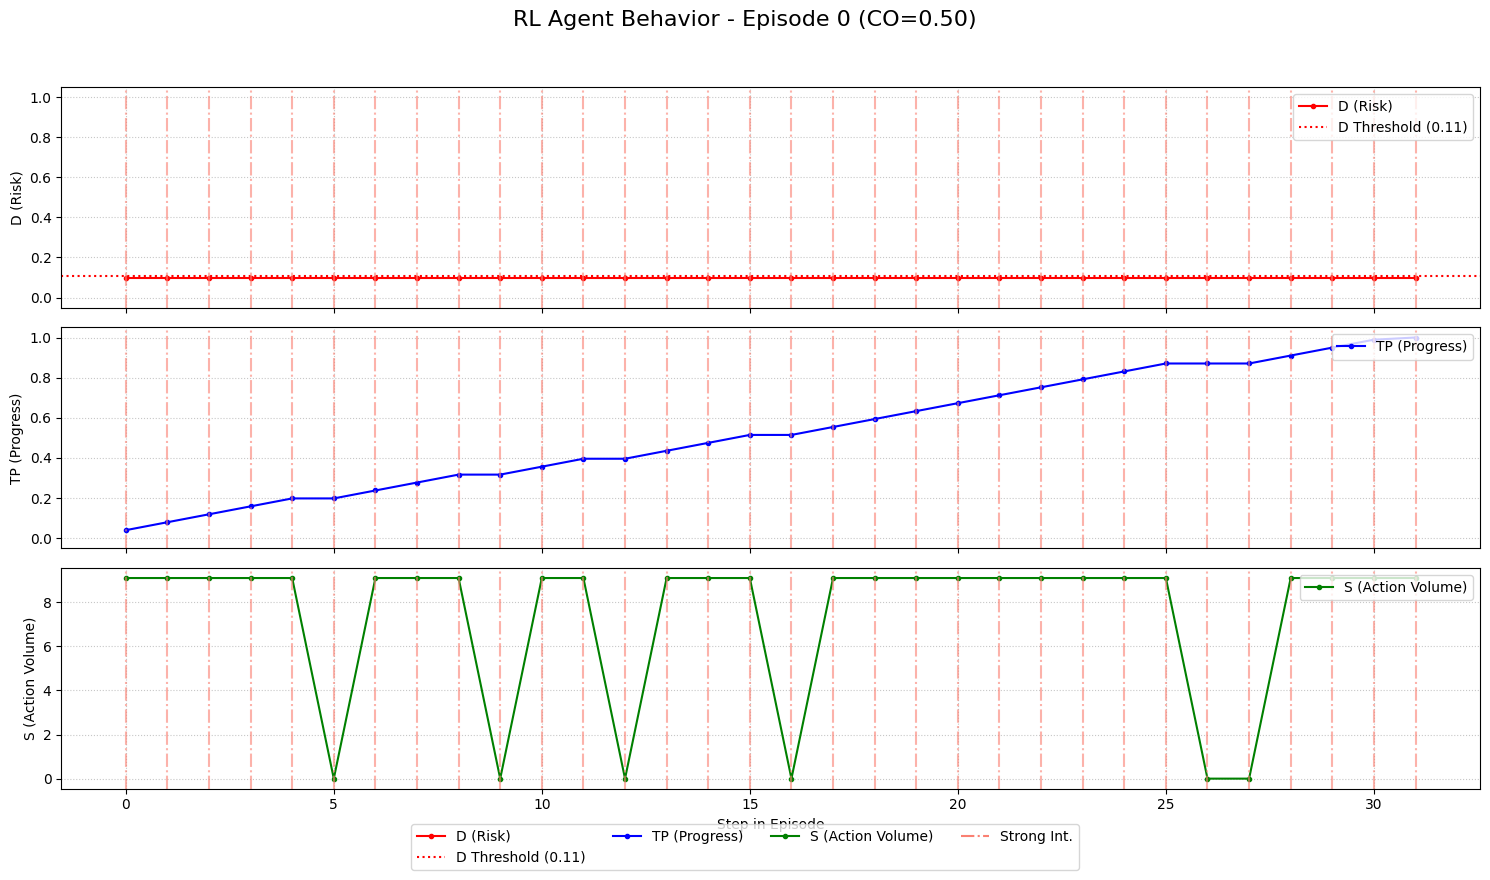

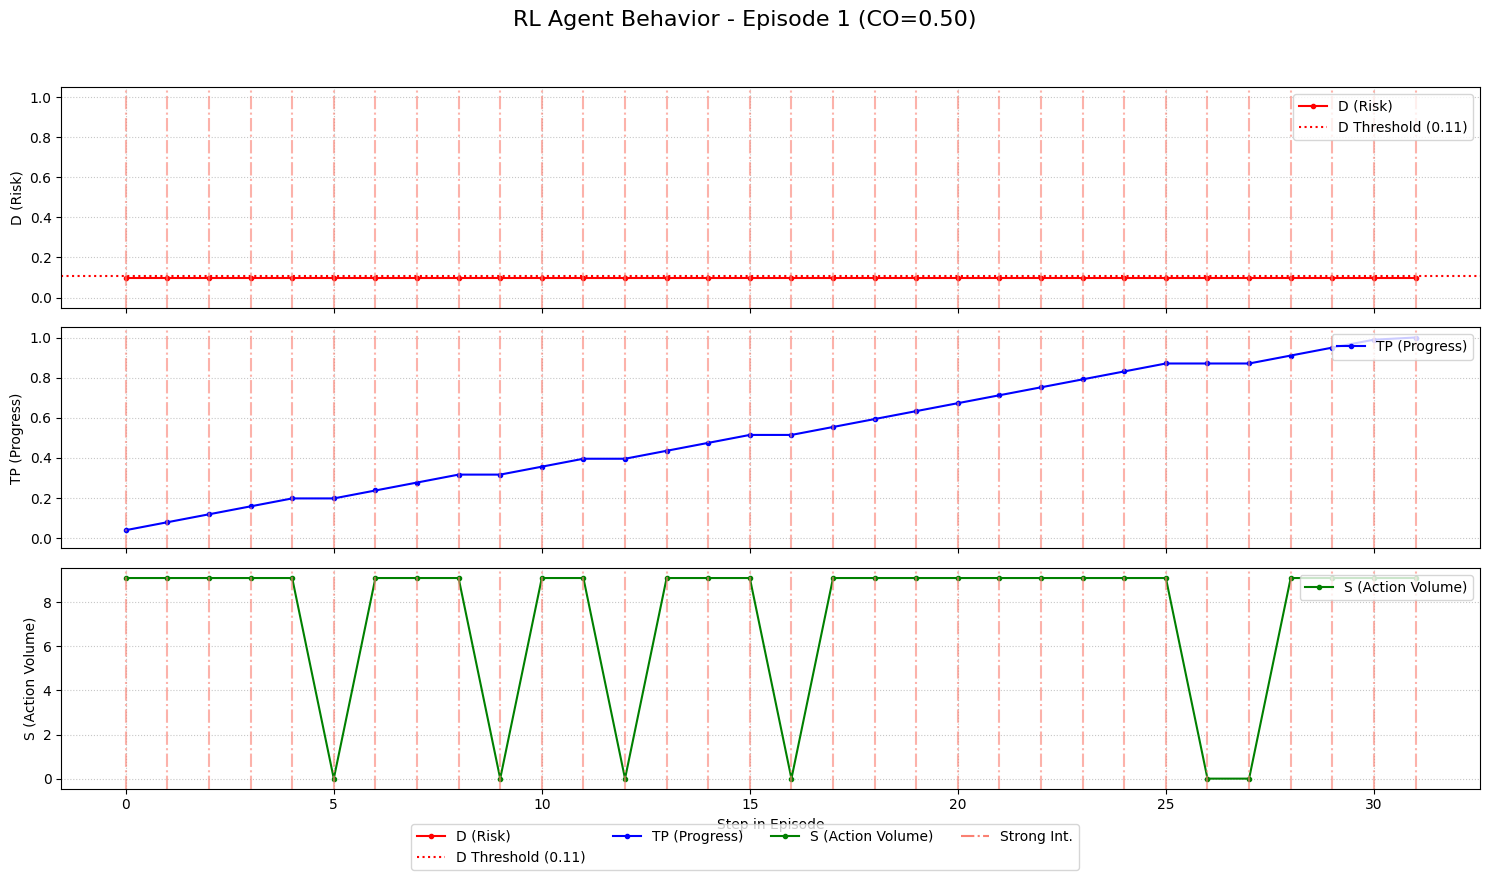


強化学習エージェントの学習と評価 完了。


In [7]:
if RUN_RL_TRAINING_AND_EVALUATION:
    print("\n--- 強化学習エージェントの学習と評価 開始 ---")
    rl_env_config = env_config_base.copy()
    rl_env_config["co_score"] = 0.5 # RLエージェントは特定のco_scoreで学習・評価
    
    def make_env_rl(): # RL用に名前を変更
        env_rl_instance = SimplifiedTaskJITAIEnv(**rl_env_config)
        env_rl_instance = Monitor(env_rl_instance)
        return env_rl_instance
    env_rl_vectorized = DummyVecEnv([make_env_rl])

    model_save_path = "ppo_jitai_agent_final"
    tensorboard_log_path = "./ppo_jitai_tensorboard_final/"
    os.makedirs(tensorboard_log_path, exist_ok=True)

    if os.path.exists(model_save_path + ".zip"):
        print(f"学習済みモデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env_rl_vectorized)
    else:
        print(f"新規モデルを作成して学習を開始します。")
        model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, vf_coef=0.5, max_grad_norm=0.5)
        print("学習中...")
        model.learn(total_timesteps=1000, tb_log_name="PPO_run_final") # ステップ数を調整
        model.save(model_save_path)
        print(f"学習済みモデルを {model_save_path}.zip に保存しました。")

    print("\n--- 学習済みRLエージェントの行動記録と評価 ---")
    num_record_episodes = 3
    rl_eval_step_data_list = []
    total_rewards_eval, total_steps_eval, completed_count_eval, disengaged_count_eval, timed_out_count_eval = 0,0,0,0,0
    
    obs_rl = env_rl_vectorized.reset()
    for episode_idx in range(num_record_episodes):
        episode_reward, episode_steps_count, done_in_episode = 0,0,False
        last_info_dict = {}
        while not done_in_episode:
            current_step_in_episode = episode_steps_count
            action_vec, _states = model.predict(obs_rl, deterministic=True)
            action_scalar = action_vec[0]
            new_obs_rl, rewards, dones, infos = env_rl_vectorized.step(action_vec)
            reward_scalar, done_in_episode, info_dict = rewards[0], dones[0], infos[0]
            
            # step_data_entry に D_threshold_value を追加
            step_data_entry = {
                'episode_id': episode_idx, 'step': current_step_in_episode, 'action_taken': action_scalar,
                'reward': reward_scalar, 'D': info_dict.get('current_D'), 'S': info_dict.get('current_S'),
                'TP': info_dict.get('current_TaskProgress'), 'CO': info_dict.get('current_CO'),
                'TR': info_dict.get('time_remaining_normalized'),
                'D_threshold_value': info_dict.get('adjusted_D_threshold'), # ここで記録
                'consecutive_inaction_steps': info_dict.get('consecutive_inaction_steps'),
                'prob_start_action_calculated': info_dict.get('prob_start_action'),
                'task_completed': info_dict.get('task_completed', False), 'disengaged': info_dict.get('disengaged', False),
                'TimeLimit.truncated': info_dict.get('TimeLimit.truncated', False)
            }
            rl_eval_step_data_list.append(step_data_entry)
            
            obs_rl = new_obs_rl
            episode_reward += reward_scalar; episode_steps_count += 1; last_info_dict = info_dict
        
        total_rewards_eval += episode_reward; total_steps_eval += episode_steps_count
        if last_info_dict.get('task_completed', False): completed_count_eval += 1
        elif last_info_dict.get('disengaged', False): disengaged_count_eval += 1
        elif done_in_episode:
            if last_info_dict.get('TimeLimit.truncated', False) and not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                timed_out_count_eval += 1
            elif not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                    timed_out_count_eval +=1
        print(f"RL評価エピソード {episode_idx + 1} 終了: 報酬={episode_reward:.2f}, ステップ数={episode_steps_count}")

    df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
    if not df_rl_eval_steps.empty:
        df_rl_eval_steps.to_csv("rl_agent_evaluation_steps.csv", index=False)
        print("\nRLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。")
    else:
        print("\nRLエージェントのステップ毎データは記録されませんでした。")

    if num_record_episodes > 0:
        print(f"\nRL評価エピソード数: {num_record_episodes}")
        print(f"平均報酬: {total_rewards_eval / num_record_episodes:.2f}")
        print(f"平均ステップ数: {total_steps_eval / num_record_episodes:.2f}")
        print(f"完了率: {completed_count_eval / num_record_episodes * 100:.1f}%")
        print(f"離脱率: {disengaged_count_eval / num_record_episodes * 100:.1f}%")
        print(f"タイムアウト率: {timed_out_count_eval / num_record_episodes * 100:.1f}%")
    
    if not df_rl_eval_steps.empty:
        plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=0, env_config=rl_env_config)
        if num_record_episodes > 1: # 記録したエピソードが複数あれば2つ目もプロット
                plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=1, env_config=rl_env_config)

    env_rl_vectorized.close()
    print("\n強化学習エージェントの学習と評価 完了。")
else:
    print("--- 強化学習エージェントの学習と評価はスキップされました ---")


--- 強化学習エージェントの学習と評価 開始 ---
学習済みモデル ppo_jitai_agent_final.zip をロードします。

--- 学習済みRLエージェントの行動記録と評価 ---
RL評価エピソード 1 終了: 報酬=56.50, ステップ数=35
RL評価エピソード 2 終了: 報酬=56.50, ステップ数=35
RL評価エピソード 3 終了: 報酬=56.50, ステップ数=35

RLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。

RL評価エピソード数: 3
平均報酬: 56.50
平均ステップ数: 35.00
完了率: 100.0%
離脱率: 0.0%
タイムアウト率: 0.0%


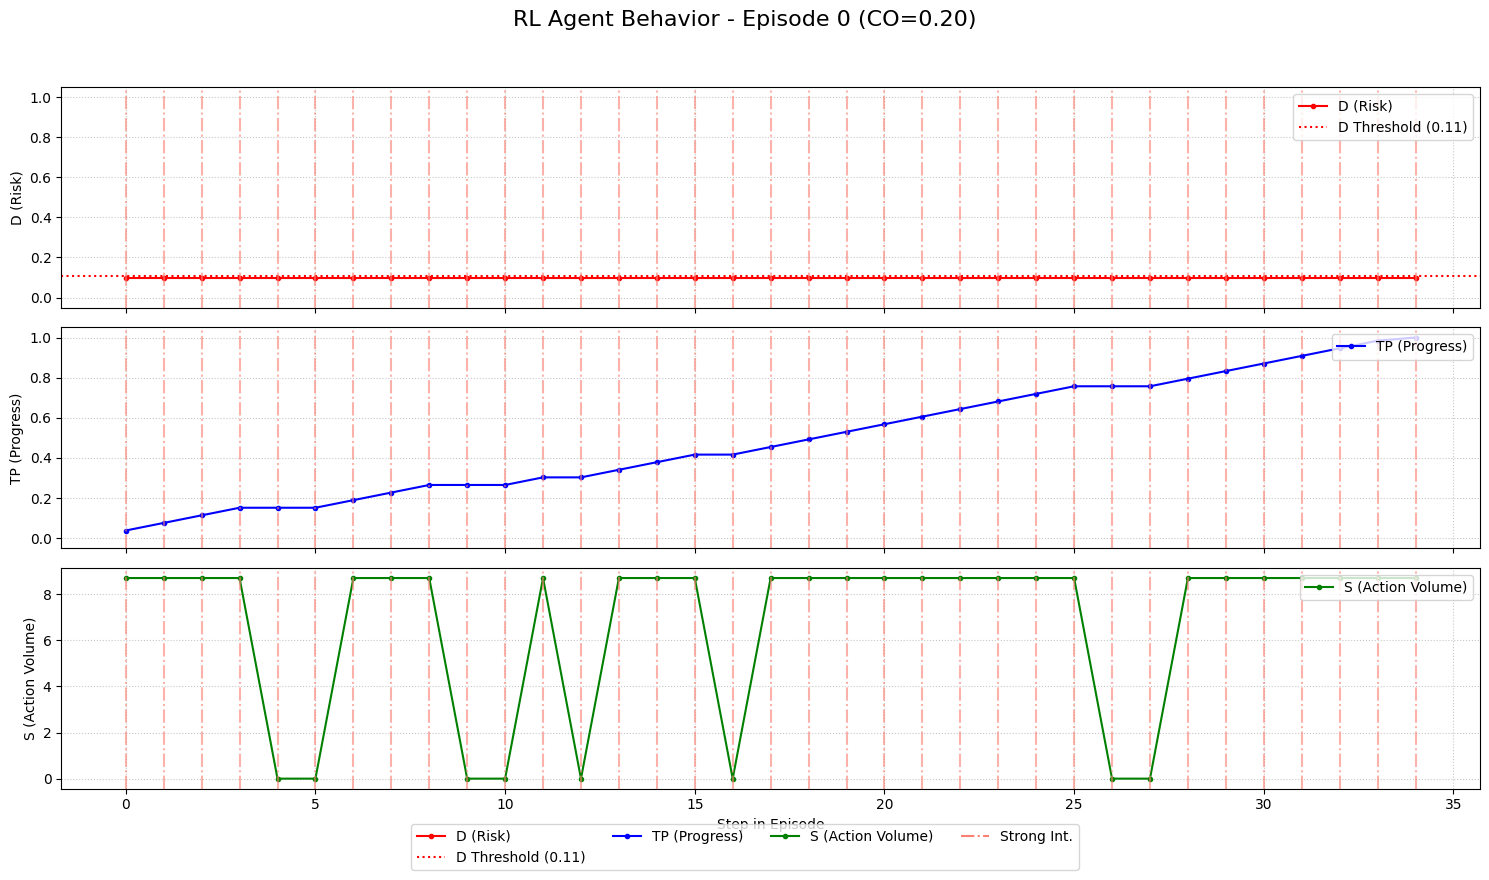

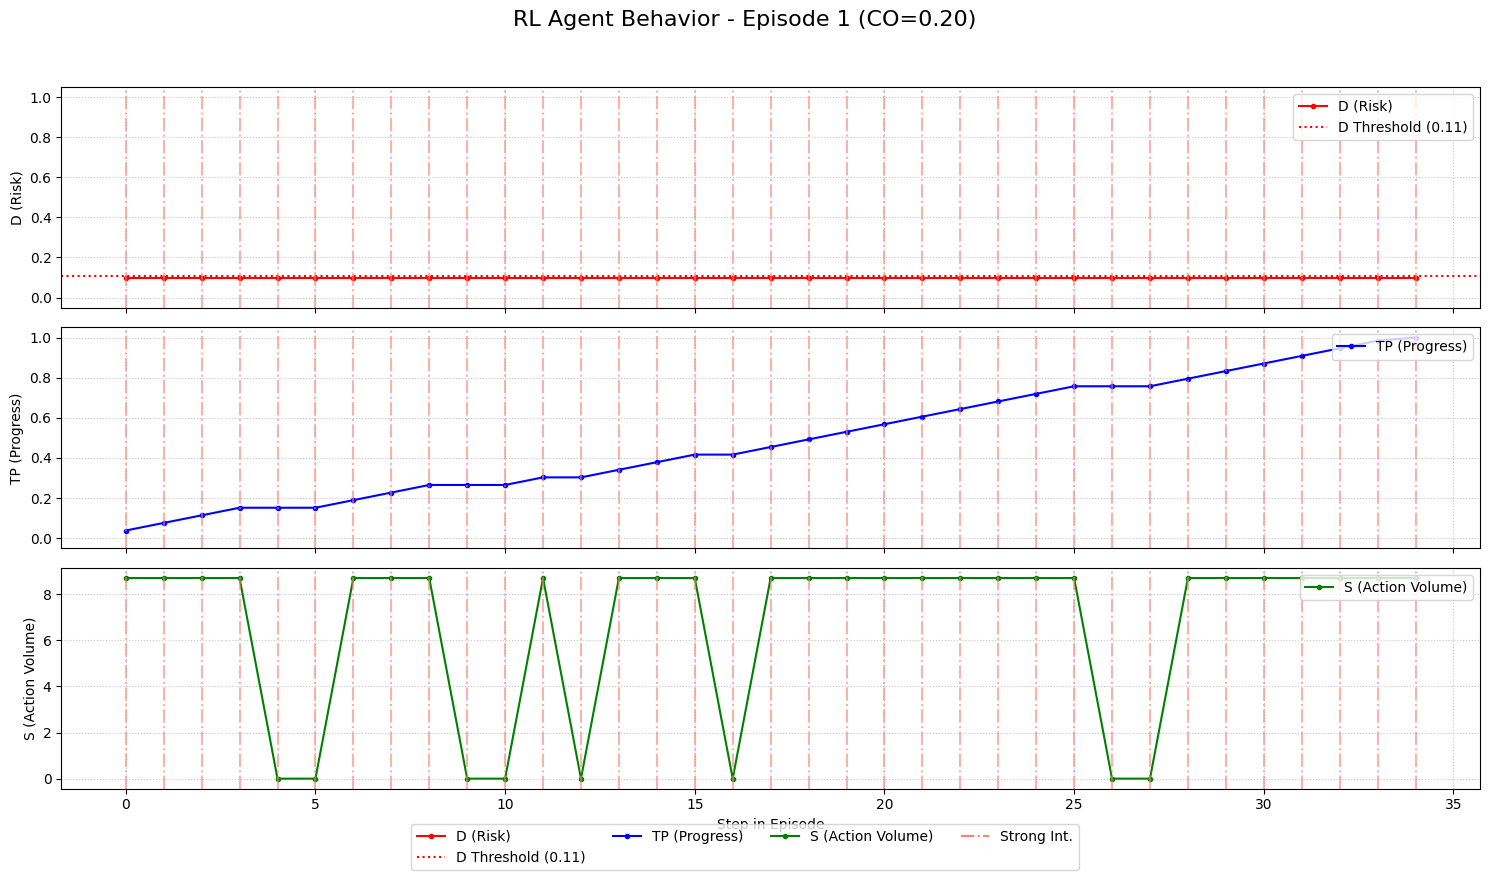


--- Plotting details for the FINAL RL evaluation episode_id = 2 ---


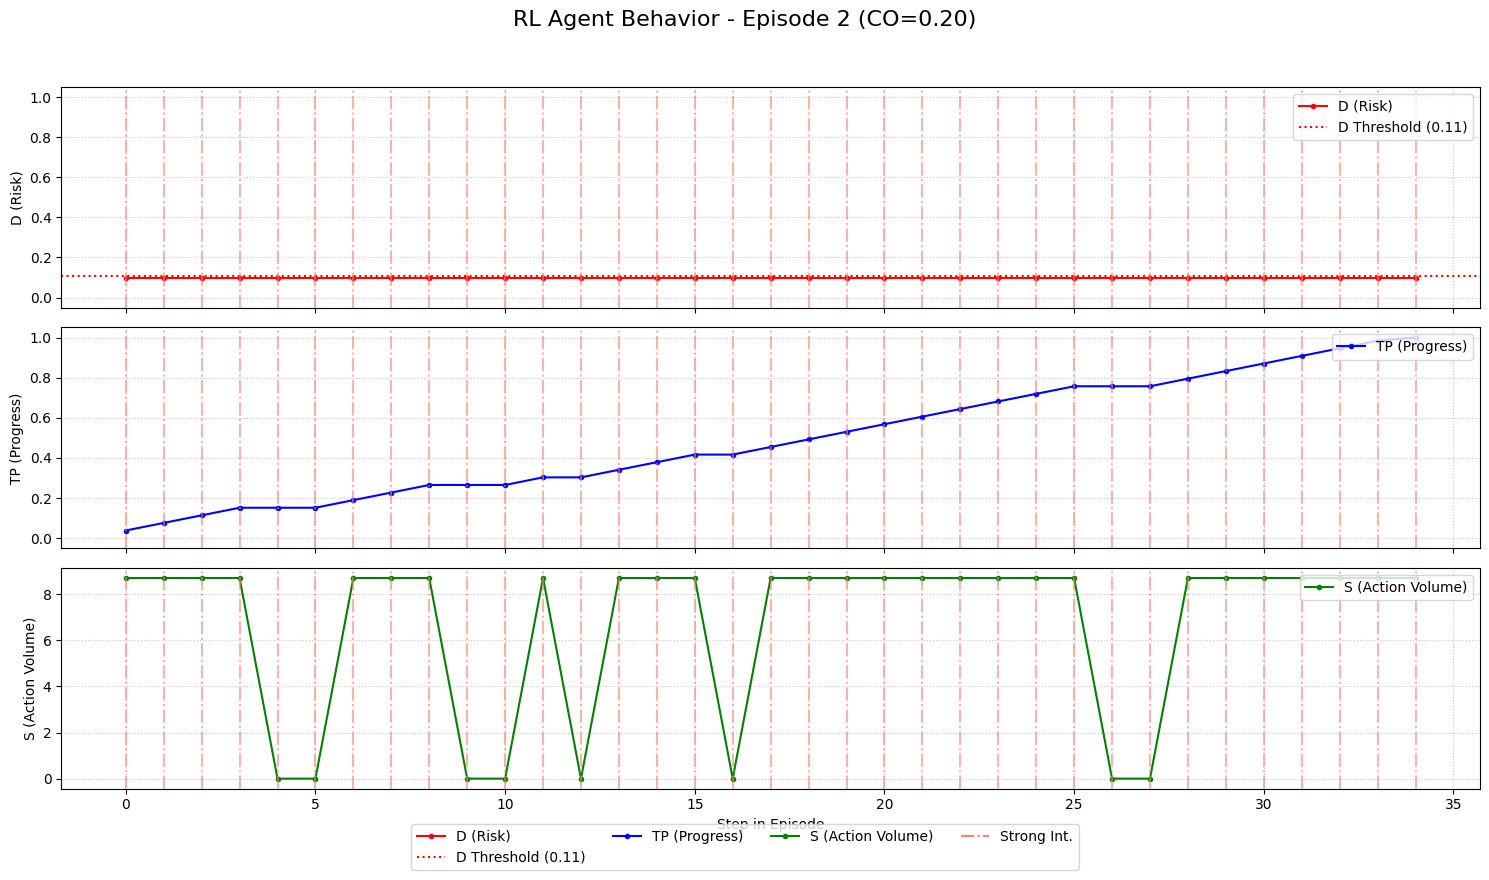


強化学習エージェントの学習と評価 完了。


In [8]:
if RUN_RL_TRAINING_AND_EVALUATION:
    print("\n--- 強化学習エージェントの学習と評価 開始 ---")
    rl_env_config = env_config_base.copy()
    rl_env_config["co_score"] = 0.2 # RLエージェントは特定のco_scoreで学習・評価
    
    def make_env_rl(): # RL用に名前を変更
        env_rl_instance = SimplifiedTaskJITAIEnv(**rl_env_config)
        env_rl_instance = Monitor(env_rl_instance)
        return env_rl_instance
    env_rl_vectorized = DummyVecEnv([make_env_rl])

    model_save_path = "ppo_jitai_agent_final"
    tensorboard_log_path = "./ppo_jitai_tensorboard_final/"
    os.makedirs(tensorboard_log_path, exist_ok=True)

    if os.path.exists(model_save_path + ".zip"):
        print(f"学習済みモデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env_rl_vectorized)
    else:
        print(f"新規モデルを作成して学習を開始します。")
        model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, vf_coef=0.5, max_grad_norm=0.5)
        print("学習中...")
        model.learn(total_timesteps=1000, tb_log_name="PPO_run_final") # ステップ数を調整
        model.save(model_save_path)
        print(f"学習済みモデルを {model_save_path}.zip に保存しました。")

    print("\n--- 学習済みRLエージェントの行動記録と評価 ---")
    num_record_episodes = 3
    rl_eval_step_data_list = []
    total_rewards_eval, total_steps_eval, completed_count_eval, disengaged_count_eval, timed_out_count_eval = 0,0,0,0,0
    
    obs_rl = env_rl_vectorized.reset()
    for episode_idx in range(num_record_episodes):
        episode_reward, episode_steps_count, done_in_episode = 0,0,False
        last_info_dict = {}
        while not done_in_episode:
            current_step_in_episode = episode_steps_count
            action_vec, _states = model.predict(obs_rl, deterministic=True)
            action_scalar = action_vec[0]
            new_obs_rl, rewards, dones, infos = env_rl_vectorized.step(action_vec)
            reward_scalar, done_in_episode, info_dict = rewards[0], dones[0], infos[0]
            
            # step_data_entry に D_threshold_value を追加
            step_data_entry = {
                'episode_id': episode_idx, 'step': current_step_in_episode, 'action_taken': action_scalar,
                'reward': reward_scalar, 'D': info_dict.get('current_D'), 'S': info_dict.get('current_S'),
                'TP': info_dict.get('current_TaskProgress'), 'CO': info_dict.get('current_CO'),
                'TR': info_dict.get('time_remaining_normalized'),
                'D_threshold_value': info_dict.get('adjusted_D_threshold'), # ここで記録
                'consecutive_inaction_steps': info_dict.get('consecutive_inaction_steps'),
                'prob_start_action_calculated': info_dict.get('prob_start_action'),
                'task_completed': info_dict.get('task_completed', False), 'disengaged': info_dict.get('disengaged', False),
                'TimeLimit.truncated': info_dict.get('TimeLimit.truncated', False)
            }
            rl_eval_step_data_list.append(step_data_entry)
            
            obs_rl = new_obs_rl
            episode_reward += reward_scalar; episode_steps_count += 1; last_info_dict = info_dict
        
        total_rewards_eval += episode_reward; total_steps_eval += episode_steps_count
        if last_info_dict.get('task_completed', False): completed_count_eval += 1
        elif last_info_dict.get('disengaged', False): disengaged_count_eval += 1
        elif done_in_episode:
            if last_info_dict.get('TimeLimit.truncated', False) and not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                timed_out_count_eval += 1
            elif not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                    timed_out_count_eval +=1
        print(f"RL評価エピソード {episode_idx + 1} 終了: 報酬={episode_reward:.2f}, ステップ数={episode_steps_count}")

    df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
    if not df_rl_eval_steps.empty:
        df_rl_eval_steps.to_csv("rl_agent_evaluation_steps.csv", index=False)
        print("\nRLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。")
    else:
        print("\nRLエージェントのステップ毎データは記録されませんでした。")

    if num_record_episodes > 0:
        print(f"\nRL評価エピソード数: {num_record_episodes}")
        print(f"平均報酬: {total_rewards_eval / num_record_episodes:.2f}")
        print(f"平均ステップ数: {total_steps_eval / num_record_episodes:.2f}")
        print(f"完了率: {completed_count_eval / num_record_episodes * 100:.1f}%")
        print(f"離脱率: {disengaged_count_eval / num_record_episodes * 100:.1f}%")
        print(f"タイムアウト率: {timed_out_count_eval / num_record_episodes * 100:.1f}%")
    
    if not df_rl_eval_steps.empty:
        plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=0, env_config=rl_env_config)
        if num_record_episodes > 1: # 記録したエピソードが複数あれば2つ目もプロット
                plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=1, env_config=rl_env_config)
# --- ★探索した最終エピソードをプロットするためのコードを追加/修正★ ---
        if num_record_episodes > 0:
            final_episode_id_to_plot = num_record_episodes - 1 # 最終エピソードのID (0から始まるため)

            # 最終エピソードが既にプロットされているか確認 (もし num_record_episodes が 1 や 2 の場合)
            # num_record_episodes が 1 なら final_episode_id は 0 (既にプロット済み)
            # num_record_episodes が 2 なら final_episode_id は 1 (既にプロット済み)
            # なので、ここでは num_record_episodes > 2 の場合にのみ追加でプロットするか、
            # 単純に final_episode_id をプロット対象として指定します。
            # ここでは、常に最終エピソードを明示的にプロットする形にします。
            
            print(f"\n--- Plotting details for the FINAL RL evaluation episode_id = {final_episode_id_to_plot} ---")
            
            # データフレーム内にそのエピソードIDのデータが存在するか確認
            if final_episode_id_to_plot in df_rl_eval_steps['episode_id'].unique():
                plot_single_episode_details(df_rl_eval_steps, 
                                            episode_id_to_plot=final_episode_id_to_plot, 
                                            env_config=rl_env_config)
            else:
                # このメッセージが出る場合、num_record_episodes と実際に記録されたエピソード数にズレがある可能性があります
                print(f"データフレームにエピソードID {final_episode_id_to_plot} のデータが見つかりませんでした。")
                print(f"記録されたエピソードID: {df_rl_eval_steps['episode_id'].unique()}")
                print(f"num_record_episodes の設定値: {num_record_episodes}")
        else:
            print("記録されたエピソードがありませんでした (num_record_episodes が0以下の可能性があります)。")
    else:
        print("RL評価データが空のため、プロットをスキップします。")
    env_rl_vectorized.close()
    print("\n強化学習エージェントの学習と評価 完了。")
else:
    print("--- 強化学習エージェントの学習と評価はスキップされました ---")

In [9]:
# ... (RL評価ループの後) ...
df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
print(f"DEBUG: df_rl_eval_steps created. Is empty? {df_rl_eval_steps.empty}")
if not df_rl_eval_steps.empty:
    print(f"DEBUG: df_rl_eval_steps shape: {df_rl_eval_steps.shape}")
    # 'action_taken' 列が存在するか確認
    if 'action_taken' in df_rl_eval_steps.columns:
        print(f"DEBUG: Relevant columns in df_rl_eval_steps head:\n{df_rl_eval_steps[['episode_id', 'step', 'action_taken']].head()}")
        print(f"DEBUG: Value counts for 'action_taken' in df_rl_eval_steps (NaNも表示):\n{df_rl_eval_steps['action_taken'].value_counts(dropna=False)}")
        print(f"DEBUG: Data type of 'action_taken': {df_rl_eval_steps['action_taken'].dtype}")
        # action_taken が NaN の行がどれくらいあるか確認
        print(f"DEBUG: Number of NaN values in 'action_taken': {df_rl_eval_steps['action_taken'].isnull().sum()}")
    else:
        print("DEBUG: ERROR - 'action_taken' column is MISSING in df_rl_eval_steps!")
# ... (以降のプロット呼び出しなど) ...

DEBUG: df_rl_eval_steps created. Is empty? False
DEBUG: df_rl_eval_steps shape: (105, 15)
DEBUG: Relevant columns in df_rl_eval_steps head:
   episode_id  step  action_taken
0           0     0             2
1           0     1             2
2           0     2             2
3           0     3             2
4           0     4             2
DEBUG: Value counts for 'action_taken' in df_rl_eval_steps (NaNも表示):
action_taken
2    105
Name: count, dtype: int64
DEBUG: Data type of 'action_taken': int64
DEBUG: Number of NaN values in 'action_taken': 0



--- 強化学習エージェントの学習と評価 開始 ---
学習済みモデル ppo_jitai_agent_final.zip をロードします。

--- 学習済みRLエージェントの行動記録と評価 ---
RL評価エピソード 1 終了: 報酬=57.10, ステップ数=29
RL評価エピソード 2 終了: 報酬=57.10, ステップ数=29
RL評価エピソード 3 終了: 報酬=57.10, ステップ数=29

RLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。

RL評価エピソード数: 3
平均報酬: 57.10
平均ステップ数: 29.00
完了率: 100.0%
離脱率: 0.0%
タイムアウト率: 0.0%


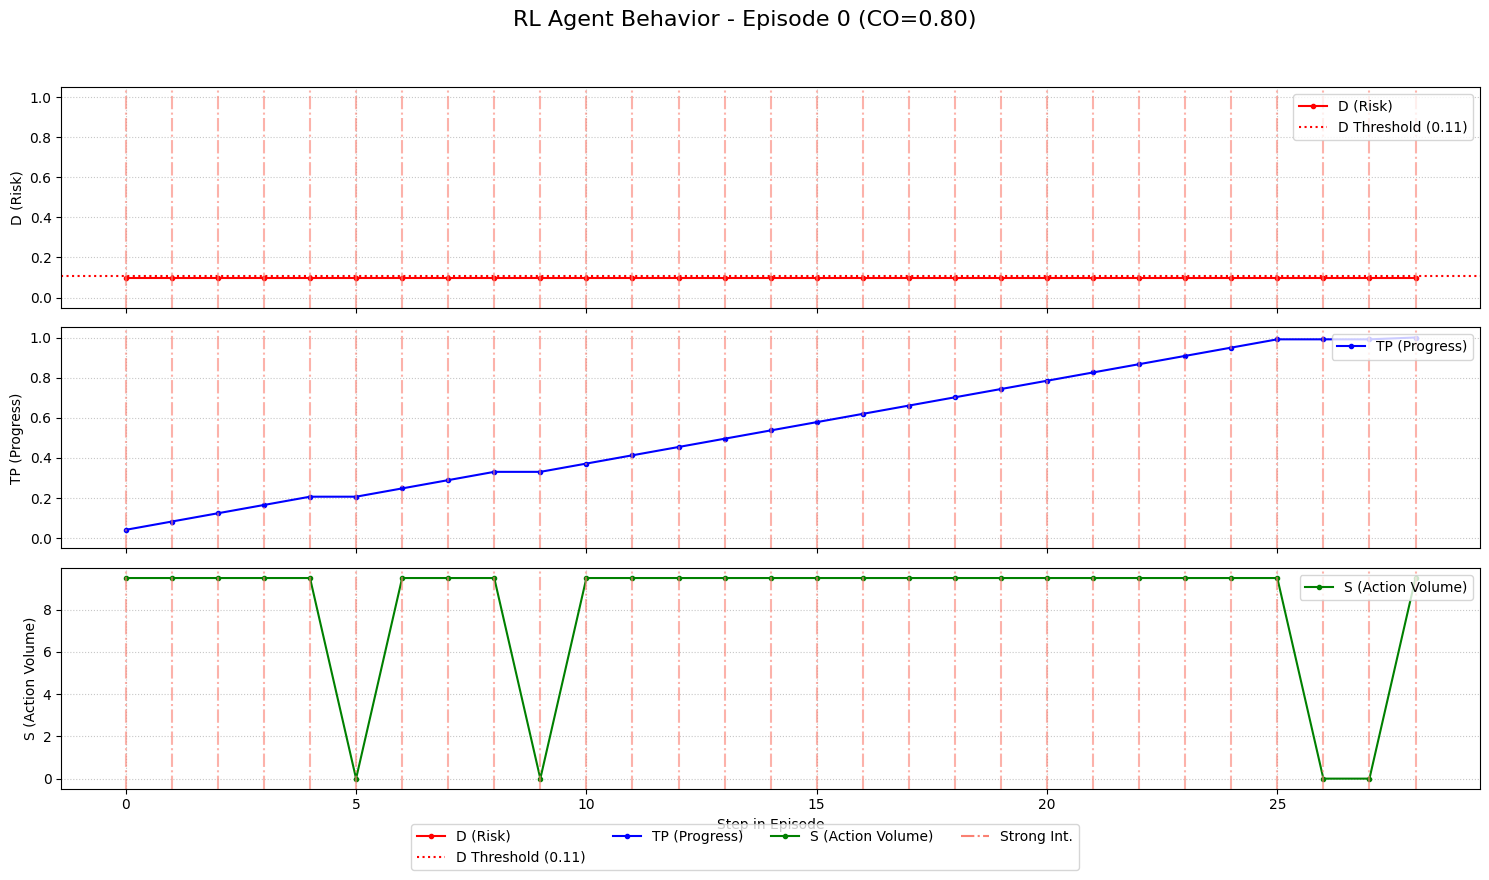

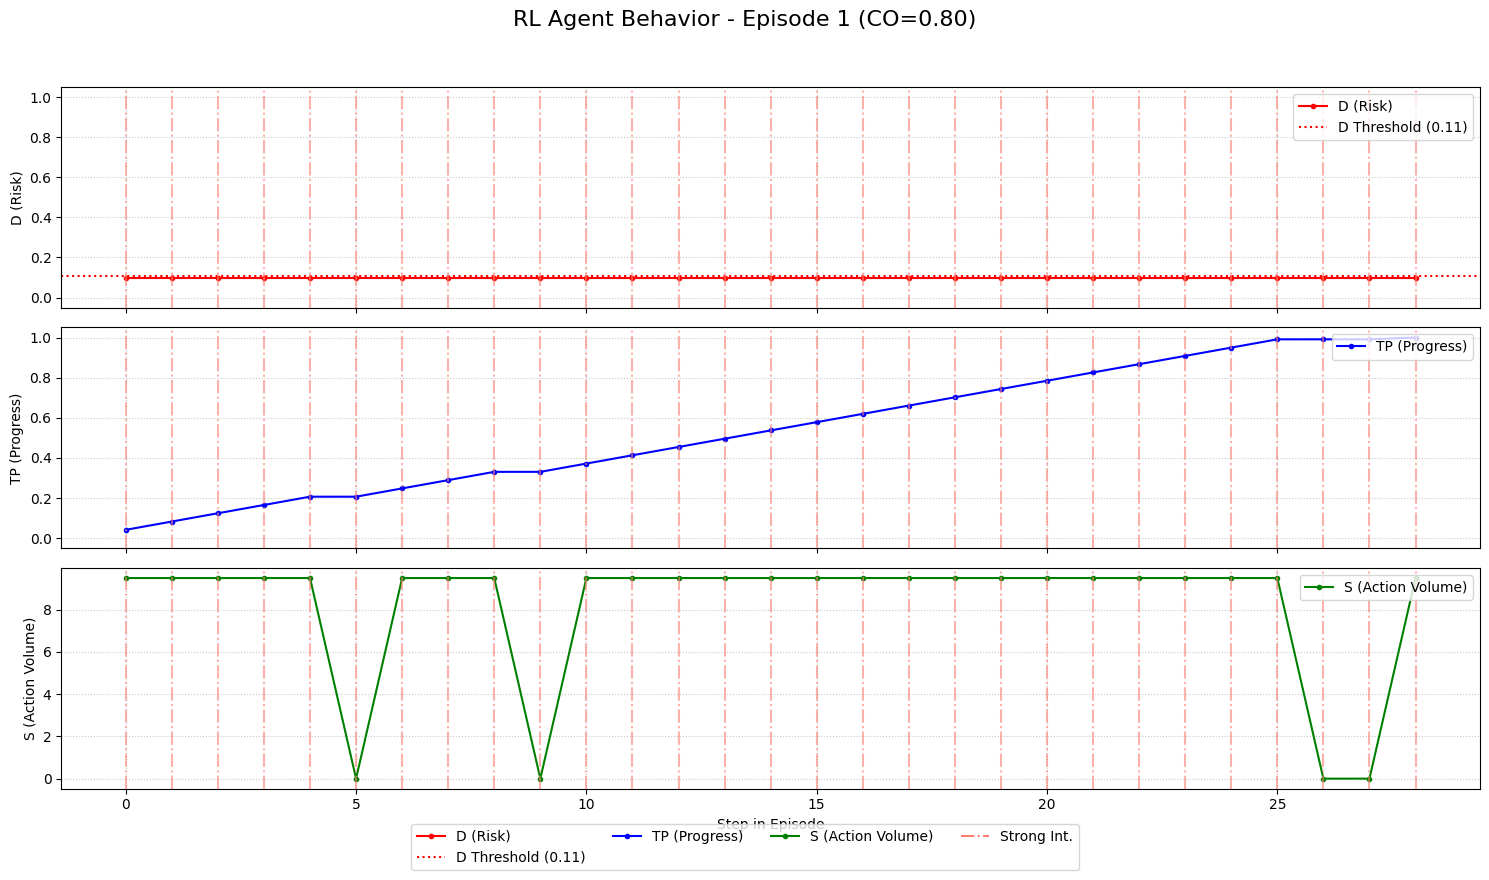


--- Plotting details for the FINAL RL evaluation episode_id = 2 ---


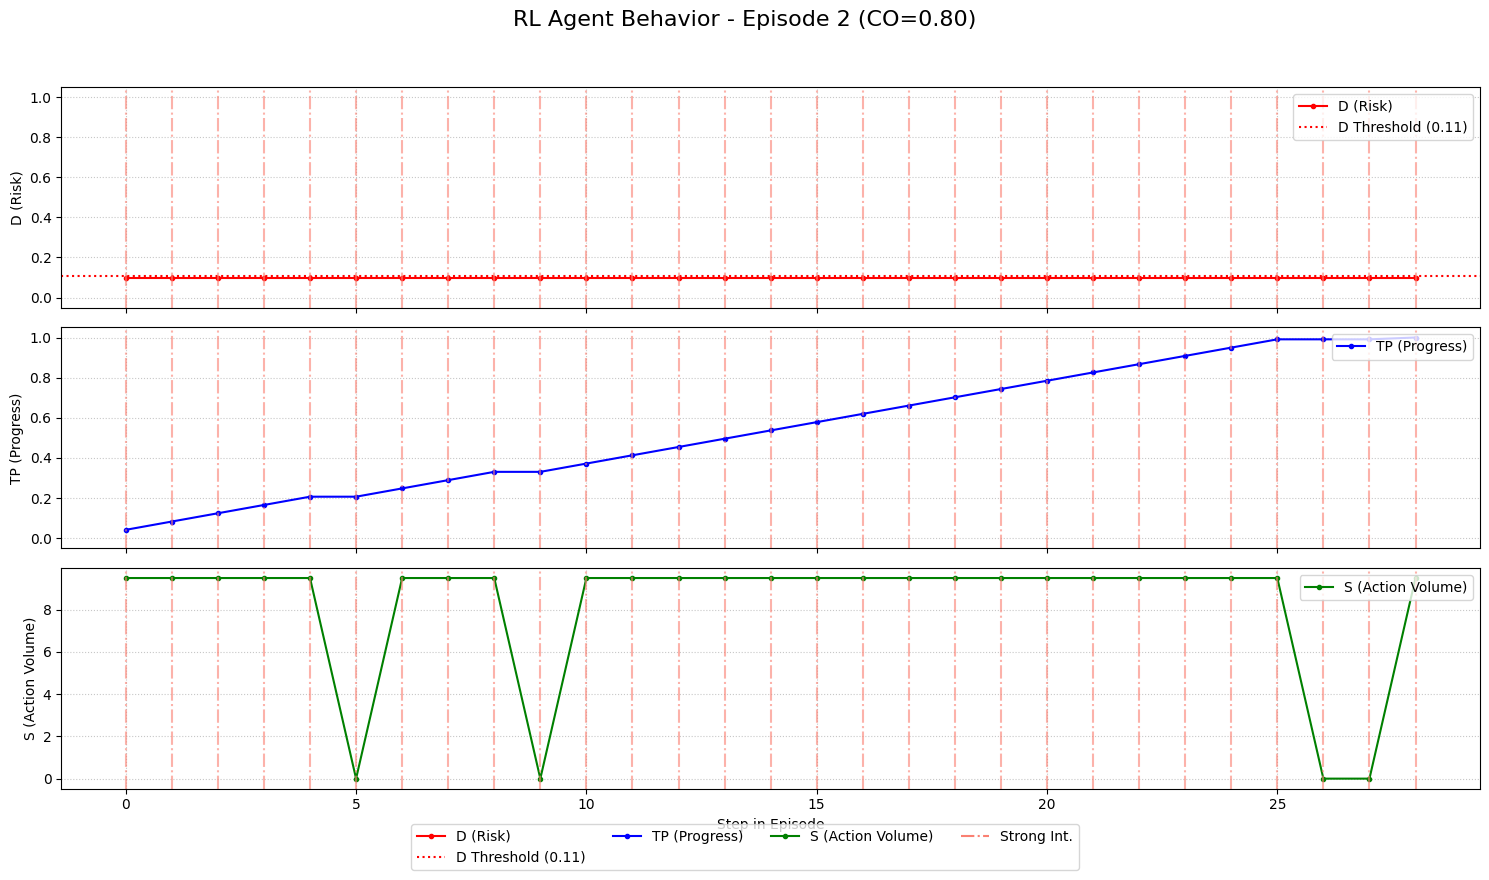


強化学習エージェントの学習と評価 完了。


In [10]:
if RUN_RL_TRAINING_AND_EVALUATION:
    print("\n--- 強化学習エージェントの学習と評価 開始 ---")
    rl_env_config = env_config_base.copy()
    rl_env_config["co_score"] = 0.8 # RLエージェントは特定のco_scoreで学習・評価
    
    def make_env_rl(): # RL用に名前を変更
        env_rl_instance = SimplifiedTaskJITAIEnv(**rl_env_config)
        env_rl_instance = Monitor(env_rl_instance)
        return env_rl_instance
    env_rl_vectorized = DummyVecEnv([make_env_rl])

    model_save_path = "ppo_jitai_agent_final"
    tensorboard_log_path = "./ppo_jitai_tensorboard_final/"
    os.makedirs(tensorboard_log_path, exist_ok=True)

    if os.path.exists(model_save_path + ".zip"):
        print(f"学習済みモデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env_rl_vectorized)
    else:
        print(f"新規モデルを作成して学習を開始します。")
        model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, vf_coef=0.5, max_grad_norm=0.5)
        print("学習中...")
        model.learn(total_timesteps=1000, tb_log_name="PPO_run_final") # ステップ数を調整
        model.save(model_save_path)
        print(f"学習済みモデルを {model_save_path}.zip に保存しました。")

    print("\n--- 学習済みRLエージェントの行動記録と評価 ---")
    num_record_episodes = 3
    rl_eval_step_data_list = []
    total_rewards_eval, total_steps_eval, completed_count_eval, disengaged_count_eval, timed_out_count_eval = 0,0,0,0,0
    
    obs_rl = env_rl_vectorized.reset()
    for episode_idx in range(num_record_episodes):
        episode_reward, episode_steps_count, done_in_episode = 0,0,False
        last_info_dict = {}
        while not done_in_episode:
            current_step_in_episode = episode_steps_count
            action_vec, _states = model.predict(obs_rl, deterministic=True)
            action_scalar = action_vec[0]
            new_obs_rl, rewards, dones, infos = env_rl_vectorized.step(action_vec)
            reward_scalar, done_in_episode, info_dict = rewards[0], dones[0], infos[0]
            
            # step_data_entry に D_threshold_value を追加
            step_data_entry = {
                'episode_id': episode_idx, 'step': current_step_in_episode, 'action_taken': action_scalar,
                'reward': reward_scalar, 'D': info_dict.get('current_D'), 'S': info_dict.get('current_S'),
                'TP': info_dict.get('current_TaskProgress'), 'CO': info_dict.get('current_CO'),
                'TR': info_dict.get('time_remaining_normalized'),
                'D_threshold_value': info_dict.get('adjusted_D_threshold'), # ここで記録
                'consecutive_inaction_steps': info_dict.get('consecutive_inaction_steps'),
                'prob_start_action_calculated': info_dict.get('prob_start_action'),
                'task_completed': info_dict.get('task_completed', False), 'disengaged': info_dict.get('disengaged', False),
                'TimeLimit.truncated': info_dict.get('TimeLimit.truncated', False)
            }
            rl_eval_step_data_list.append(step_data_entry)
            
            obs_rl = new_obs_rl
            episode_reward += reward_scalar; episode_steps_count += 1; last_info_dict = info_dict
        
        total_rewards_eval += episode_reward; total_steps_eval += episode_steps_count
        if last_info_dict.get('task_completed', False): completed_count_eval += 1
        elif last_info_dict.get('disengaged', False): disengaged_count_eval += 1
        elif done_in_episode:
            if last_info_dict.get('TimeLimit.truncated', False) and not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                timed_out_count_eval += 1
            elif not last_info_dict.get('task_completed', False) and not last_info_dict.get('disengaged', False):
                    timed_out_count_eval +=1
        print(f"RL評価エピソード {episode_idx + 1} 終了: 報酬={episode_reward:.2f}, ステップ数={episode_steps_count}")

    df_rl_eval_steps = pd.DataFrame(rl_eval_step_data_list)
    if not df_rl_eval_steps.empty:
        df_rl_eval_steps.to_csv("rl_agent_evaluation_steps.csv", index=False)
        print("\nRLエージェントのステップ毎データが rl_agent_evaluation_steps.csv に保存されました。")
    else:
        print("\nRLエージェントのステップ毎データは記録されませんでした。")

    if num_record_episodes > 0:
        print(f"\nRL評価エピソード数: {num_record_episodes}")
        print(f"平均報酬: {total_rewards_eval / num_record_episodes:.2f}")
        print(f"平均ステップ数: {total_steps_eval / num_record_episodes:.2f}")
        print(f"完了率: {completed_count_eval / num_record_episodes * 100:.1f}%")
        print(f"離脱率: {disengaged_count_eval / num_record_episodes * 100:.1f}%")
        print(f"タイムアウト率: {timed_out_count_eval / num_record_episodes * 100:.1f}%")
    
    if not df_rl_eval_steps.empty:
        plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=0, env_config=rl_env_config)
        if num_record_episodes > 1: # 記録したエピソードが複数あれば2つ目もプロット
                plot_single_episode_details(df_rl_eval_steps, episode_id_to_plot=1, env_config=rl_env_config)
# --- ★探索した最終エピソードをプロットするためのコードを追加/修正★ ---
        if num_record_episodes > 0:
            final_episode_id_to_plot = num_record_episodes - 1 # 最終エピソードのID (0から始まるため)

            # 最終エピソードが既にプロットされているか確認 (もし num_record_episodes が 1 や 2 の場合)
            # num_record_episodes が 1 なら final_episode_id は 0 (既にプロット済み)
            # num_record_episodes が 2 なら final_episode_id は 1 (既にプロット済み)
            # なので、ここでは num_record_episodes > 2 の場合にのみ追加でプロットするか、
            # 単純に final_episode_id をプロット対象として指定します。
            # ここでは、常に最終エピソードを明示的にプロットする形にします。
            
            print(f"\n--- Plotting details for the FINAL RL evaluation episode_id = {final_episode_id_to_plot} ---")
            
            # データフレーム内にそのエピソードIDのデータが存在するか確認
            if final_episode_id_to_plot in df_rl_eval_steps['episode_id'].unique():
                plot_single_episode_details(df_rl_eval_steps, 
                                            episode_id_to_plot=final_episode_id_to_plot, 
                                            env_config=rl_env_config)
            else:
                # このメッセージが出る場合、num_record_episodes と実際に記録されたエピソード数にズレがある可能性があります
                print(f"データフレームにエピソードID {final_episode_id_to_plot} のデータが見つかりませんでした。")
                print(f"記録されたエピソードID: {df_rl_eval_steps['episode_id'].unique()}")
                print(f"num_record_episodes の設定値: {num_record_episodes}")
        else:
            print("記録されたエピソードがありませんでした (num_record_episodes が0以下の可能性があります)。")
    else:
        print("RL評価データが空のため、プロットをスキップします。")
    env_rl_vectorized.close()
    print("\n強化学習エージェントの学習と評価 完了。")
else:
    print("--- 強化学習エージェントの学習と評価はスキップされました ---")